In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt   # fixed: was "import matplotlib as plt", which breaks plt.figure()

# relative path instead of C:/Users/..., change it if your folder layout is different
df = pd.read_parquet("../Data/processed/Cleaned.parquet")
print(df.head())

                     Global_active_power  Global_reactive_power  Voltage  \
DateTime                                                                   
2006-12-16 17:24:00                4.216                  0.418   234.84   
2006-12-16 17:25:00                5.360                  0.436   233.63   
2006-12-16 17:26:00                5.374                  0.498   233.29   
2006-12-16 17:27:00                5.388                  0.502   233.74   
2006-12-16 17:28:00                3.666                  0.528   235.68   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
DateTime                                                                
2006-12-16 17:24:00              18.4             0.0             1.0   
2006-12-16 17:25:00              23.0             0.0             1.0   
2006-12-16 17:26:00              23.0             0.0             2.0   
2006-12-16 17:27:00              23.0             0.0             1.0   
2006-12-16 17:28:00          

In [4]:
print(df.shape)
df.columns.to_list()

(2075259, 8)


['Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'hour']

In [15]:
# Resample the data--------------------------------------
power = df["Global_active_power"].resample("15min").mean()

In [16]:
# create historical consumption features-----------------------------
data = pd.DataFrame({
    "power": power
})

# current value: known at prediction time, was missing before (the model only saw t-1 and older)
data["lag_0"] = data["power"]
data["lag_1"] = data["power"].shift(1)
data["lag_2"] = data["power"].shift(2)
data["lag_4"] = data["power"].shift(4)
data["lag_96"] = data["power"].shift(96)

In [17]:
# rolling average features-------------------------------
# removed .shift(1) so the windows end at the current time t (not leakage, since the target is t+1)
data["rolling_mean_1h"] = (
    data["power"].rolling(4).mean()
)

data["rolling_mean_6h"] = (
    data["power"].rolling(24).mean()
)

In [18]:
# time-based features--------------------------------------
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek
data["month"] = data.index.month
data["is_weekend"] = (
    data["day_of_week"] >= 5
).astype(int)

C:\Users\danya\AppData\Local\Temp\ipykernel_9096\3583196258.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  data["day_of_week"] = data.index.dayofweek


In [1]:
# prediction target-------------------------
data["target"] = data["power"].shift(-1)

# baselines for comparison, built before dropna so they stay aligned with the target
data["persistence"] = data["power"]               # next 15 min = current value
data["seasonal_naive"] = data["power"].shift(95)  # same time yesterday (96 steps before the target)

# remove rows that don't have all required values------
data = data.dropna()

NameError: name 'data' is not defined

In [20]:
# splitting data-------------------------------------
# baseline columns are kept out of the features
X = data.drop(columns=["power", "target", "persistence", "seasonal_naive"])

y = data["target"]

n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

In [21]:
# A: Linear Regression-----------------------------------
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

In [22]:
# B: Random Forest Regressor----------------------------
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [23]:
# C: XGBoost----------------------------------------
from xgboost import XGBRegressor

# validation set is now used: training stops when validation error stops improving
xgb_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    early_stopping_rounds=50,
    random_state=42
)

xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

xgb_predictions = xgb_model.predict(X_test)

In [24]:
# Evaluate Forecasting Models----------------------------
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    return mae, rmse, r2

In [25]:
# Compare Models-----------------------------
# the two baselines show whether the models actually learned something
models = {
    "Persistence (baseline)": data.loc[X_test.index, "persistence"],
    "Seasonal naive (baseline)": data.loc[X_test.index, "seasonal_naive"],
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

for name, predictions in models.items():

    mae, rmse, r2 = evaluate_model(
        y_test,
        predictions
    )

    print(name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)
    print("----------------")

Persistence (baseline)
MAE: 0.29031301818181815
RMSE: 0.4914056226663207
R2: 0.6229179158278191
----------------
Seasonal naive (baseline)
MAE: 0.609303846811675
RMSE: 0.9146385015055843
R2: -0.3063351538098267
----------------
Linear Regression
MAE: 0.2887258324585525
RMSE: 0.4630585945117967
R2: 0.6651675392601906
----------------
Random Forest
MAE: 0.2709055251148601
RMSE: 0.4428116778450937
R2: 0.6938080368664918
----------------
XGBoost
MAE: 0.2703512934848877
RMSE: 0.4380451183980951
R2: 0.7003644449839722
----------------


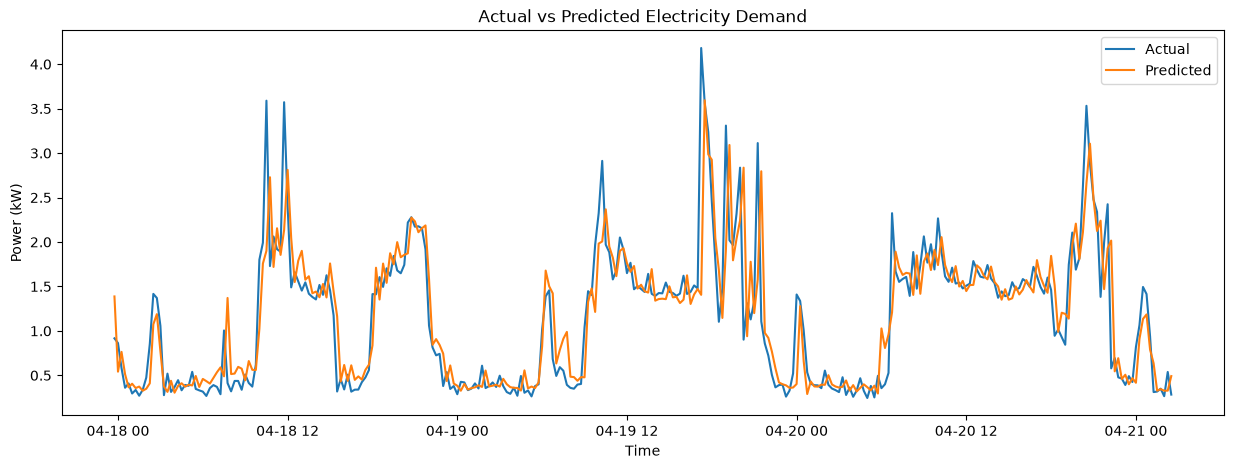

In [26]:
# Comparison Graphs-----------------------------
plt.figure(figsize=(15, 5))

plt.plot(
    y_test.index[:300],
    y_test.iloc[:300],
    label="Actual"
)

plt.plot(
    y_test.index[:300],
    xgb_predictions[:300],
    label="Predicted"
)

plt.legend()
plt.title("Actual vs Predicted Electricity Demand")
plt.xlabel("Time")
plt.ylabel("Power (kW)")

plt.show()

In [28]:
import joblib

joblib.dump(
    xgb_model,
    "../Models/load_forecasting_model.pkl"
)



['../Models/load_forecasting_model.pkl']